# How far does return similarity reach, and does a track record travel?

**Takeaway.** Films that share people have similar returns, but only when they share them directly: two steps apart
in the network the similarity is gone. The more people two films share, the more alike their returns. Films with
similar scripts and no shared people are no more alike than random films. And when someone makes a film at a studio
that's new to them, their own track record predicts little, while the new studio's record predicts as much as ever.

This notebook reads the saved outputs of three scripts and needs no raw data:

| Script | Question | Output |
|---|---|---|
| `scripts/network/pair_returns.py` | Which film pairs have similar returns? | `analysis/network/pair_returns.json` |
| `scripts/network/team_history.py` | Do teams that worked together before return more? | `analysis/network/team_history.json` |
| `scripts/network/movers.py` | Does a person's record follow them to a new studio? | `analysis/network/movers.json` |

All three use the 6,851 clean movies in the graph. The return is ln(gross / budget) net of ln(budget), release
decade and genre, so "similar returns" means similar after those are accounted for. Gross over budget isn't
profit: marketing is missing and cinemas keep part of the gross.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO = Path.cwd().resolve().parent   # notebooks -> repo root
SRC = REPO / "analysis" / "network"
pairs = json.loads((SRC / "pair_returns.json").read_text())
teams = json.loads((SRC / "team_history.json").read_text())["results"]
movers = json.loads((SRC / "movers.json").read_text())["results"]

INK, ACCENT, GREY, LIGHT, RED = "#1F2933", "#1F6F8B", "#8A969C", "#D5E3E8", "#B5482F"
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.float_format", lambda v: f"{v:+.3f}")
VARIANTS = {"all": "All films", "no_franchise": "No franchise films", "rank": "Ranked returns"}
print(f"{pairs['films']:,} films, {pairs['shuffles']:,} shuffles per null")

6,851 films, 1,000 shuffles per null


## 1. Film pairs

Two films are linked when they share a key person: a director, writer, producer, top-three cast member, composer,
cinematographer or editor. For a set of film pairs we take the mean of z_i × z_j, where z is the standardised
return. That is the correlation between the two films of a pair, and it's 0 for random pairs.

Every null shuffles returns across films 1,000 times and keeps the network as it is. `null 95%` is the 95th
percentile when returns are shuffled across all films, and `studio null 95%` when they are shuffled only among
films of the same main studio.

### 1.1 Distance: only direct links count

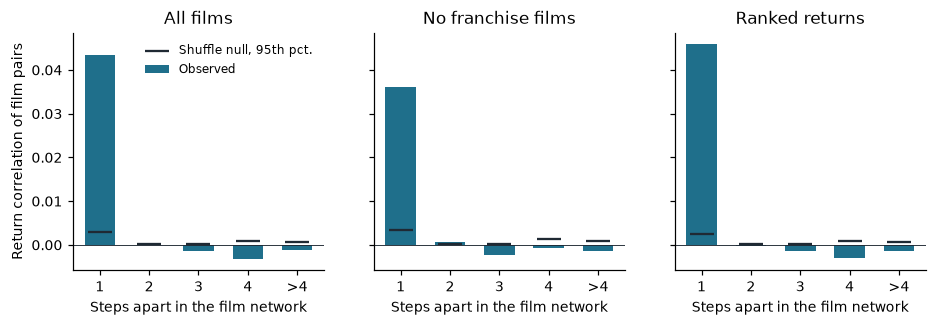

,pairs,correlation,null 95%,same-year null 95%,studio null 95%
1,"185,584",+0.036,+0.004,+0.003,+0.019
2,"5,638,330",+0.001,+0.000,+0.000,+0.001
3,"5,802,451",-0.002,+0.000,+0.000,-0.000
4,"680,281",-0.001,+0.001,+0.001,+0.001
>4,"311,130",-0.001,+0.001,+0.001,-0.000


In [2]:
def pair_table(part, variant):
    rows = pairs["graph"][variant][part]
    return pd.DataFrame({k: {"pairs": f"{r['pairs']:,}", "correlation": r["corr"], "null 95%": r["null_all_95"],
                             "same-year null 95%": r["null_year_95"], "studio null 95%": r["null_studio_95"]}
                         for k, r in rows.items()}).T

def pair_bars(ax, part, variant, nulls=("all",)):
    rows = pairs["graph"][variant][part]
    x = np.arange(len(rows))
    ax.bar(x, [r["corr"] for r in rows.values()], color=ACCENT, width=0.62, label="Observed")
    ax.scatter(x, [r["null_all_95"] for r in rows.values()], marker="_", s=260, color=INK, zorder=3,
               label="Shuffle null, 95th pct.")
    if "studio" in nulls:
        ax.scatter(x, [r["null_studio_95"] for r in rows.values()], marker="x", s=40, color=RED, zorder=3,
                   label="Null within studio, 95th pct.")
    ax.axhline(0, color=INK, lw=0.6)
    ax.set_xticks(x, list(rows))
    ax.set_title(VARIANTS[variant])

fig, axes = plt.subplots(1, 3, figsize=(10, 2.8), sharey=True)
for ax, v in zip(axes, VARIANTS):
    pair_bars(ax, "distance", v)
    ax.set_xlabel("Steps apart in the film network")
axes[0].set_ylabel("Return correlation of film pairs")
axes[0].legend(frameon=False, fontsize=8)
plt.show()
pair_table("distance", "no_franchise")

**Reading it.** Films one step apart correlate well above the null. At two steps the correlation is already
at zero, and it stays there. So the similarity belongs to the people two films share, not to the part of the
network a film sits in. It holds without franchise films and with ranked returns.

The small negative values further out are arithmetic. Standardised returns sum to zero, so if linked pairs sit
above zero, the remaining pairs have to sit a little below.

### 1.2 Shared people: the more two films share, the more alike

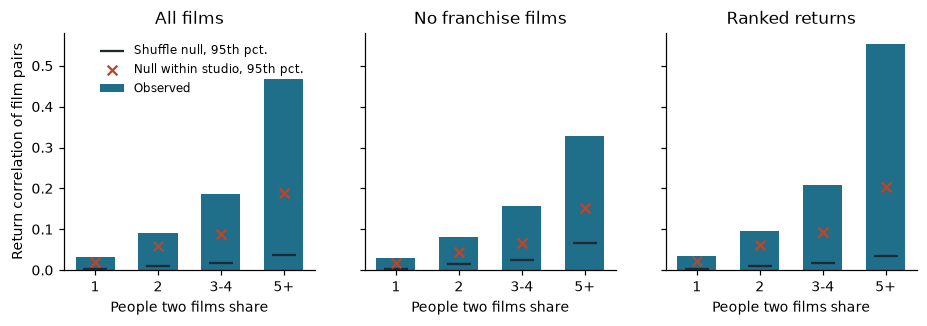

,pairs,correlation,null 95%,same-year null 95%,studio null 95%
1,"168,312",+0.029,+0.004,+0.004,+0.017
2,"12,551",+0.081,+0.015,+0.015,+0.044
3-4,"4,087",+0.157,+0.026,+0.027,+0.067
5+,634,+0.328,+0.066,+0.064,+0.152


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(10, 2.8), sharey=True)
for ax, v in zip(axes, VARIANTS):
    pair_bars(ax, "dose", v, nulls=("all", "studio"))
    ax.set_xlabel("People two films share")
axes[0].set_ylabel("Return correlation of film pairs")
axes[0].legend(frameon=False, fontsize=8)
plt.show()
pair_table("dose", "no_franchise")

**Reading it.** The correlation rises with every step, and each step stays above the null that shuffles
only within a studio, so this isn't just two films coming from the same company. The top group is small, and the
franchise flag is rough, so some of the pairs sharing five or more people are still sequels the flag missed.

### 1.3 People and companies both carry it

In [4]:
pd.concat({VARIANTS[v]: pair_table("company", v) for v in ("all", "no_franchise")})

pairs correlation null 95%  \
All films          linked_no_shared_company    269,863      +0.023   +0.003   
                   linked_shared_company        74,311      +0.117   +0.006   
                   unlinked_shared_company   1,492,206      +0.025   +0.001   
No franchise films linked_no_shared_company    150,055      +0.022   +0.004   
                   linked_shared_company        35,529      +0.093   +0.008   
                   unlinked_shared_company     723,114      +0.033   +0.002   

                                            same-year null 95% studio null 95%  
All films          linked_no_shared_company             +0.003          +0.012  
                   linked_shared_company                +0.006          +0.077  
                   unlinked_shared_company              +0.001          +0.018  
No franchise films linked_no_shared_company             +0.004          +0.012  
                   linked_shared_company                +0.009          +0.054  
                   unlinked_shared_company              +0.002          +0.022

**Reading it.** Linked films with no studio or distributor in common are still alike, and so are films
that share a company and no person. Neither explains the other away.

### 1.4 Scripts: similar scripts, no similar returns

For films with a screenplay embedding (the mean all-MiniLM-L6-v2 vector of a script's passages), we compare pairs
that share a person with the same number of unlinked pairs whose scripts are the most similar, and then follow
unlinked pairs across deciles of script similarity.

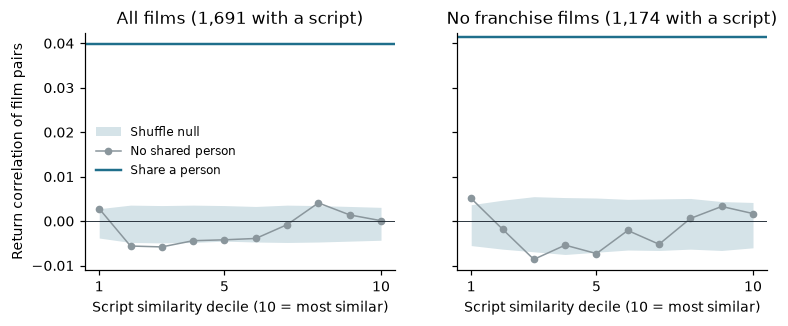

,pairs,correlation,null 95%,same-year null 95%
linked,"17,603",+0.041,+0.011,+0.011
unlinked most similar scripts,"17,603",+0.004,+0.011,+0.011
unlinked rest,"653,345",-0.002,-0.000,-0.000
linked similar scripts,"8,802",+0.045,+0.015,+0.017
linked dissimilar scripts,"8,801",+0.038,+0.017,+0.017


In [5]:
def script_table(variant):
    s = pairs["scripts"][variant]["pairs"]
    return pd.DataFrame({k.replace("_", " "): {"pairs": f"{r['pairs']:,}", "correlation": r["corr"],
                                                "null 95%": r["null_all_95"], "same-year null 95%": r["null_year_95"]}
                         for k, r in s.items()}).T

fig, axes = plt.subplots(1, 2, figsize=(8, 2.8), sharey=True)
for ax, v in zip(axes, ("all", "no_franchise")):
    s = pairs["scripts"][v]
    dec = s["unlinked_by_cosine_decile"]
    x = np.arange(1, 11)
    ax.fill_between(x, [2 * r["null_all_mean"] - r["null_all_95"] for r in dec], [r["null_all_95"] for r in dec],
                    color=LIGHT, lw=0, label="Shuffle null")
    ax.plot(x, [r["corr"] for r in dec], "o-", color=GREY, ms=4, lw=1, label="No shared person")
    ax.axhline(s["pairs"]["linked"]["corr"], color=ACCENT, lw=1.6, label="Share a person")
    ax.axhline(0, color=INK, lw=0.6)
    ax.set_xticks([1, 5, 10])
    ax.set_xlabel("Script similarity decile (10 = most similar)")
    ax.set_title(f"{VARIANTS[v]} ({s['films']:,} with a script)")
axes[0].set_ylabel("Return correlation of film pairs")
axes[0].legend(frameon=False, fontsize=8, loc="center left")
plt.show()
script_table("no_franchise")

In [6]:
pd.set_option("display.float_format", lambda v: f"{v:.4f}")
sim = pd.DataFrame({VARIANTS[v]: pairs["scripts"][v]["script_similarity"] for v in ("all", "no_franchise")})
display(sim)
pd.set_option("display.float_format", lambda v: f"{v:+.3f}")

,All films,No franchise films
cosine_linked,0.6324,0.6372
cosine_unlinked,0.6159,0.6230
cosine_linked_same_genre,0.6614,0.6638
cosine_unlinked_same_genre,0.6417,0.6477
same_genre_gap,0.0197,0.0160
same_genre_gap_null_95,0.0004,0.0024
same_genre_gap_p,0.0050,0.0050
cosine_sd_all_pairs,0.0952,0.0931


**Reading it.** Pairs that share a person are alike in return. Unlinked pairs are not, however similar
their scripts: the line stays inside the null band in every decile. People do make somewhat similar films (within
the same first genre, linked films' scripts are closer than unlinked ones, and `same_genre_gap` is above its null),
but that gap is small next to the spread across all pairs (`cosine_sd_all_pairs`).

**What this measures and misses.** The pair correlation says returns cluster. It uses every year at once, so it
isn't a prediction. Cosine similarity between mean passage vectors captures shared topic and vocabulary, not
quality or structure.

## 2. Teams that have worked together before

`repeat_share` is the share of pairs in a film's team who share an earlier film. `newcomer_share` is the share of
the team with no earlier film in the graph. Both use films from earlier years only, over all 12,673 films in the
graph. `rho` is the Spearman correlation with the adjusted return, and `rho_partial` is the same net of the team's
own track record, experience and size. The null shuffles returns among films released in the same year.

In [7]:
def measure_table(variant):
    m = teams[variant]["measures"]
    return pd.DataFrame({k: {"films": f"{r['films']:,}", "rho": r["rho"], "null 5%": r["rho_null_05"],
                             "null 95%": r["rho_null_95"], "rho_partial": r["rho_partial"],
                             "p (partial)": r["rho_partial_p_two_sided"]} for k, r in m.items()}).T

pd.concat({VARIANTS[v]: measure_table(v) for v in ("all", "no_franchise")})

films    rho null 5% null 95% rho_partial  \
All films          repeat_share    6,851 +0.127  -0.011   +0.028      +0.082   
                   any_repeat      6,851 +0.013  -0.017   +0.021      -0.038   
                   newcomer_share  6,851 -0.081  -0.030   +0.009      -0.024   
No franchise films repeat_share    5,024 +0.077  -0.016   +0.029      +0.024   
                   any_repeat      5,024 +0.022  -0.020   +0.025      -0.025   
                   newcomer_share  5,024 -0.063  -0.030   +0.015      +0.006   

                                  p (partial)  
All films          repeat_share        +0.001  
                   any_repeat          +0.002  
                   newcomer_share      +0.047  
No franchise films repeat_share        +0.097  
                   any_repeat          +0.106  
                   newcomer_share      +0.662

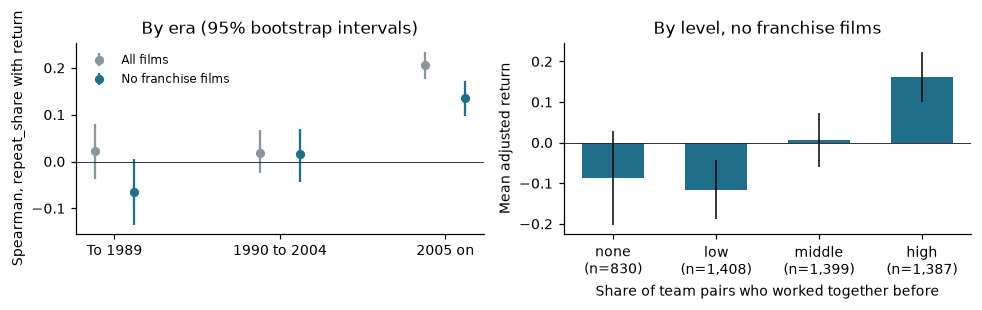

,All films,No franchise films
"out-of-time R2 (fitted to 2010, tested 2011 to 2017)",,
track_experience_size,+0.041,+0.031
plus_repeat_share,+0.059,+0.032
plus_repeat_and_newcomer,+0.061,+0.033
gain from repeat_share,+0.018,+0.001


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(9, 2.8))
eras = {"to_1989": "To 1989", "1990_2004": "1990 to 2004", "2005_on": "2005 on"}
for off, (v, col) in zip((-0.12, 0.12), (("all", GREY), ("no_franchise", ACCENT))):
    e = teams[v]["eras"]
    rho = np.array([e[k]["rho"] for k in eras])
    ci = np.array([e[k]["rho_ci"] for k in eras])
    axes[0].errorbar(np.arange(3) + off, rho, yerr=[rho - ci[:, 0], ci[:, 1] - rho], fmt="o", color=col, ms=5,
                     label=VARIANTS[v])
axes[0].axhline(0, color=INK, lw=0.6)
axes[0].set_xticks(range(3), list(eras.values()))
axes[0].set_ylabel("Spearman, repeat_share with return")
axes[0].set_title("By era (95% bootstrap intervals)")
axes[0].legend(frameon=False, fontsize=8)
lev = teams["no_franchise"]["levels"]
axes[1].bar(range(4), [l["return_mean"] for l in lev], yerr=[1.96 * l["return_se"] for l in lev], color=ACCENT,
            width=0.6, error_kw={"lw": 1})
axes[1].axhline(0, color=INK, lw=0.6)
axes[1].set_xticks(range(4), [f"{l['level']}\n(n={l['films']:,})" for l in lev])
axes[1].set_xlabel("Share of team pairs who worked together before")
axes[1].set_ylabel("Mean adjusted return")
axes[1].set_title("By level, no franchise films")
plt.tight_layout()
plt.show()
oot = pd.DataFrame({VARIANTS[v]: {**teams[v]["out_of_time"]["r2"],
                                  "gain from repeat_share": teams[v]["out_of_time"]["gain_plus_repeat_share"]}
                    for v in ("all", "no_franchise")})
oot.index.name = "out-of-time R2 (fitted to 2010, tested 2011 to 2017)"
oot

**Reading it.** With franchise films, teams that have worked together before return more, and the measure
adds a little to prediction on later films. Most of that is sequels. Without franchise films the correlation
shrinks, it can't be told from zero once the team's own track record, experience and size are accounted for, and
the out-of-time gain all but disappears.

What remains sits in films from 2005 on. We haven't tested why, and sequels the flag missed are one candidate.

**What this measures and misses.** "Earlier film" means an earlier film with 10,000+ IMDb votes, so a newcomer may
have a long career in smaller films. IMDb's principals file lists about ten people a title, so teams are partial.
Studios may also reunite teams for projects they already expect to do well, so none of this is causal.

## 3. Movers: does a track record travel?

The unit is one credit: a director, writer, producer or top-three cast member on a film, where the person has at
least two earlier clean films and the film's studios have at least five that the person didn't work on. A credit
is a **mover** when none of the film's studios appears on any of the person's earlier films, and a **stayer**
otherwise.

We regress the film's adjusted return on two records built from earlier films only: the person's, and the
studio's without that person's films. Both are standardised, so a coefficient is the change in return (in SDs)
for one SD of the record. For a mover the person's record was earned entirely at other studios, so its
coefficient is the part that travels. Intervals resample people.

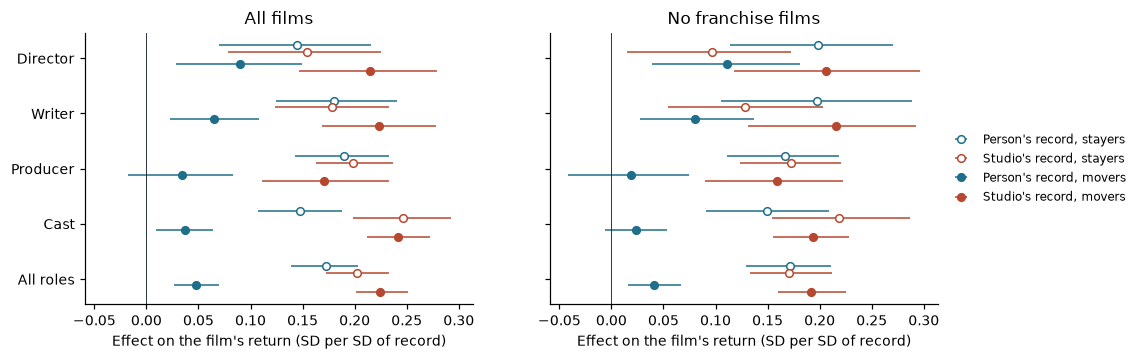

credits person     person 95% CI person p studio  \
director movers      750 +0.111  +0.039 to +0.181    0.001 +0.206   
         stayers     722 +0.198  +0.114 to +0.271    0.001 +0.096   
writer   movers    1,077 +0.080  +0.027 to +0.137    0.016 +0.216   
         stayers     817 +0.197  +0.106 to +0.288    0.001 +0.128   
producer movers    1,276 +0.019  -0.042 to +0.075    0.337 +0.159   
         stayers   2,760 +0.166  +0.111 to +0.219    0.001 +0.172   
cast     movers    3,668 +0.024  -0.006 to +0.053    0.094 +0.193   
         stayers   1,658 +0.150  +0.091 to +0.209    0.001 +0.218   
any      movers    6,771 +0.041  +0.016 to +0.067    0.002 +0.192   
         stayers   5,957 +0.171  +0.129 to +0.211    0.001 +0.171   

                     studio 95% CI  
director movers   +0.118 to +0.296  
         stayers  +0.015 to +0.172  
writer   movers   +0.132 to +0.292  
         stayers  +0.055 to +0.203  
producer movers   +0.090 to +0.222  
         stayers  +0.124 to +0.221  
cast     movers   +0.155 to +0.228  
         stayers  +0.154 to +0.286  
any      movers   +0.160 to +0.225  
         stayers  +0.133 to +0.212

In [9]:
ROLES = ["director", "writer", "producer", "cast", "any"]

def mover_table(variant):
    rows = {}
    for role in ROLES:
        for group in ("movers", "stayers"):
            r = movers[variant][role][group]
            rows[(role, group)] = {"credits": f"{r['credits']:,}", "person": r["person"],
                                   "person 95% CI": f"{r['person_ci'][0]:+.3f} to {r['person_ci'][1]:+.3f}",
                                   "person p": f"{r['person_p']:.3f}", "studio": r["studio"],
                                   "studio 95% CI": f"{r['studio_ci'][0]:+.3f} to {r['studio_ci'][1]:+.3f}"}
    return pd.DataFrame(rows).T

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharex=True, sharey=True)
y = np.arange(len(ROLES))[::-1]
for ax, v in zip(axes, ("all", "no_franchise")):
    for off, group, hollow in ((0.17, "stayers", True), (-0.17, "movers", False)):
        for kind, col, nudge in (("person", ACCENT, 0.06), ("studio", RED, -0.06)):
            est = np.array([movers[v][r][group][kind] for r in ROLES])
            ci = np.array([movers[v][r][group][f"{kind}_ci"] for r in ROLES])
            ax.errorbar(est, y + off + nudge, xerr=[est - ci[:, 0], ci[:, 1] - est], fmt="o", ms=5, color=col,
                        mfc="white" if hollow else col, lw=1, label=f"{kind.capitalize()}'s record, {group}")
    ax.axvline(0, color=INK, lw=0.6)
    ax.set_yticks(y, [r.capitalize() if r != "any" else "All roles" for r in ROLES])
    ax.set_xlabel("Effect on the film's return (SD per SD of record)")
    ax.set_title(VARIANTS[v])
axes[1].legend(frameon=False, fontsize=8, loc="center left", bbox_to_anchor=(1.0, 0.5))
plt.show()
mover_table("no_franchise")

**Reading it.** For stayers the person's record and the studio's predict about equally. For movers the
person's record predicts about a quarter as much, while the new studio's record predicts as much as ever.
Directors keep the most after a move, then writers. Producers' and cast members' records can't be told from zero
at a new studio.

One worry is noise. A person's record rests on a few films and a studio's on many, and a noisier record gets a
smaller coefficient for that reason alone. The check below builds both records from exactly three films: the
person's three most recent, and three drawn at random from the studio's (averaged over 50 draws).

In [10]:
rows = {}
for v in ("all", "no_franchise"):
    for group in ("movers", "stayers"):
        r = movers[v]["any"][group]
        rows[(VARIANTS[v], group)] = {"person films (median)": f"{r['person_films_median']:.0f}",
                                      "studio films (median)": f"{r['studio_films_median']:.0f}",
                                      "person, full": r["person"], "studio, full": r["studio"],
                                      "credits (matched)": f"{r['matched']['credits']:,}",
                                      "person, 3 films": r["matched"]["person"],
                                      "studio, 3 films": r["matched"]["studio"]}
pd.DataFrame(rows).T

person films (median) studio films (median)  \
All films          movers                      5                    27   
                   stayers                     8                    53   
No franchise films movers                      5                    22   
                   stayers                     7                    39   

                           person, full studio, full credits (matched)  \
All films          movers        +0.048       +0.225             8,730   
                   stayers       +0.172       +0.203            10,282   
No franchise films movers        +0.041       +0.192             5,267   
                   stayers       +0.171       +0.171             5,204   

                           person, 3 films studio, 3 films  
All films          movers           +0.062          +0.136  
                   stayers          +0.215          +0.108  
No franchise films movers           +0.053          +0.116  
                   stayers          +0.176          +0.084

**Reading it.** With equally short records the pattern holds: for movers the studio's record still
predicts about twice what the person's does, and for stayers it's the other way round.

**What this measures and misses.** Moves aren't random. A studio hires someone for a project it has already
chosen, so a mover's coefficient is not what would happen if people were reassigned to studios. "Studio" is the
production company in the Wikipedia infobox, and a film with several studios counts as a stay if any of them is
familiar. Histories cover films with 10,000+ IMDb votes only.

## 4. Rebuild

From the data folder, after the graph and `franchise_flag.py`:

```bash
../../.venv/bin/python ../../scripts/network/pair_returns.py
../../.venv/bin/python ../../scripts/network/team_history.py
../../.venv/bin/python ../../scripts/network/movers.py
```

Then from the repo root, `python scripts/network/network_figures.py` redraws the paper-style figure and
`python scripts/network/build_notebook.py` rebuilds this notebook.